# 🌾 Smart Harvest Yield Prediction for Precision Farming
### Academic Final Year Project - Model Development Workflow

This notebook details the full machine learning engineering workflow for predicting agricultural crop yield based on environmental weather features, soil health attributes, and N-P-K nutrient parameters. 

---

### 🧠 Precision Agriculture Overview
Precision Farming (or Precision Agriculture) uses technology-driven insights to optimize field-level management, particularly with regard to crop cultivation. By predicting crop yields dynamically using soil characteristics and real-time/expected weather forecasts, farmers can:
1. **Select the best crop** for their regional climate and soil type.
2. **Optimize nutrient inputs** (Nitrogen, Phosphorus, Potassium) to reduce costs and avoid chemical runoff.
3. **Improve yields** by anticipating weather deviations and planning harvests accordingly.

---

### ⚙️ Machine Learning Workflow:
- **Data Loading & Inspections**: Ingest agricultural survey records.
- **Exploratory Data Analysis (EDA)**: Render 5 crop-wise and environmental charts.
- **Feature Engineering**: Create agronomic ratios (total N-P-K, temperature/humidity ratios).
- **Preprocessing**: Encode labels for states, districts, crops, and seasons. Scale all values.
- **Model Training & Evaluation**: Train a Random Forest Regressor and report MAE, RMSE, and $R^2$ scores.
- **Serialization**: Export the trained model, label encoders, features list, and scaler to `.joblib` files.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

# Set visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries successfully imported!")

Libraries successfully imported!


In [2]:
# Load the dataset
dataset_path = "dataset.csv"
if not os.path.exists(dataset_path):
    print("dataset.csv not found! Run the dataset generator first.")
else:
    df = pd.read_csv(dataset_path)
    print(f"Dataset Loaded successfully! Shape: {df.shape}")
    print("\n--- First 5 Columns of Crop Yield Records ---")
    display(df.head())
    print("\n--- Descriptive Summary ---")
    display(df.describe())

Dataset Loaded successfully! Shape: (5000, 14)

--- First 5 Columns of Crop Yield Records ---


,state,district,crop,season,area,rainfall,temperature,humidity,soil_type,ph,nitrogen,phosphorus,potassium,yield
0,Karnataka,Mysuru,Sugarcane,Whole Year,866.28,1962.71,25.60,70.01,Sandy,8.23,176.60,65.62,60.91,63.11
1,Maharashtra,Jalgaon,Cotton,Kharif,152.63,863.87,36.63,48.17,Alluvial,7.04,107.39,27.32,56.45,2.36
2,Uttar Pradesh,Meerut,Tomato,Rabi,4272.54,2273.09,19.37,60.41,Black,5.57,132.75,47.94,129.75,13.33
3,Telangana,Nizamabad,Groundnut,Kharif,4364.65,921.28,29.13,31.19,Black,6.31,29.43,28.57,59.72,1.31
4,Telangana,Karimnagar,Cotton,Kharif,2751.30,764.42,23.22,58.82,Sandy,7.63,123.21,55.30,75.58,1.96



--- Descriptive Summary ---


,area,rainfall,temperature,humidity,ph,nitrogen,phosphorus,potassium,yield
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2269.39060,941.828558,25.693158,64.087492,6.695644,107.985496,57.607628,69.860446,17.659188
std,1289.20125,678.780218,6.557390,14.232892,0.907150,38.517128,18.137223,36.552492,26.038381
min,50.47000,57.120000,10.170000,25.010000,4.000000,10.210000,15.320000,10.010000,0.730000
25%,1159.28250,408.967500,20.930000,53.620000,6.040000,86.407500,43.782500,40.472500,2.520000
50%,2256.19000,760.510000,25.700000,64.180000,6.680000,113.485000,57.375000,62.675000,3.980000
75%,3418.43750,1326.387500,30.480000,74.117500,7.380000,135.552500,70.912500,98.940000,21.992500
max,4498.21000,2799.290000,41.940000,94.950000,8.990000,189.830000,104.920000,149.950000,113.170000


### 🧹 Data Cleaning and Missing Value Treatment
Real agriculture datasets have missing records and outliers due to sensor errors or recording failures. We inspect missing cells, duplicates, and clean the data before model fitting.

In [3]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicates
duplicates = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicate rows dropped!")

print("\nUnique categorical factors:")
for col in ['state', 'district', 'crop', 'season', 'soil_type']:
    print(f"- {col}: {df[col].nunique()} unique classes")

Missing values per column:
state          0
district       0
crop           0
season         0
area           0
rainfall       0
temperature    0
humidity       0
soil_type      0
ph             0
nitrogen       0
phosphorus     0
potassium      0
yield          0
dtype: int64

Duplicate rows found: 0

Unique categorical factors:
- state: 8 unique classes
- district: 40 unique classes
- crop: 8 unique classes
- season: 4 unique classes
- soil_type: 6 unique classes


### 📊 Exploratory Data Analysis (EDA)
Let's create academic-grade visualizations to inspect the feature distributions and trends.

C:\Users\sanga\AppData\Local\Temp\ipykernel_28320\2243003892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=crop_yield.values, y=crop_yield.index, palette="viridis")


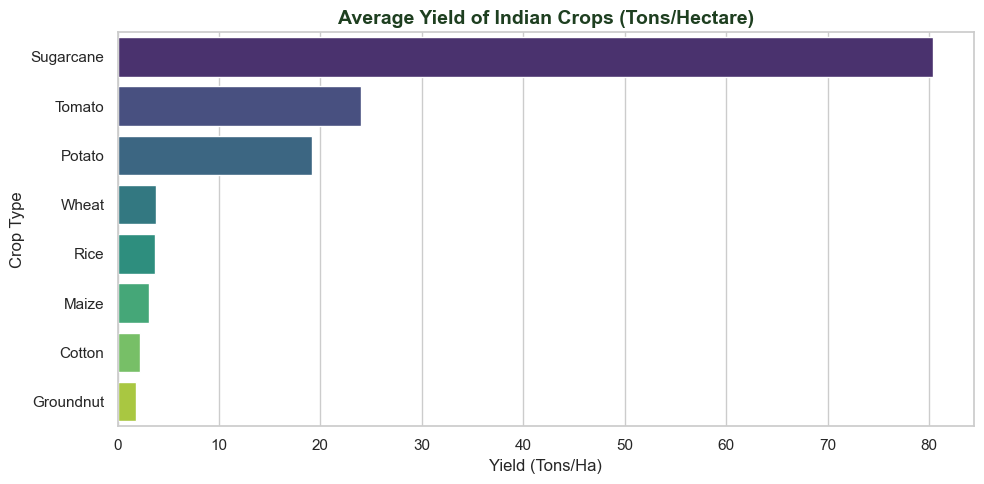

In [4]:
plt.figure(figsize=(10, 5))
crop_yield = df.groupby('crop')['yield'].mean().sort_values(ascending=False)
sns.barplot(x=crop_yield.values, y=crop_yield.index, palette="viridis")
plt.title("Average Yield of Indian Crops (Tons/Hectare)", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Yield (Tons/Ha)", fontsize=12)
plt.ylabel("Crop Type", fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\sanga\AppData\Local\Temp\ipykernel_28320\424359155.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=state_yield.values, y=state_yield.index, palette="crest")


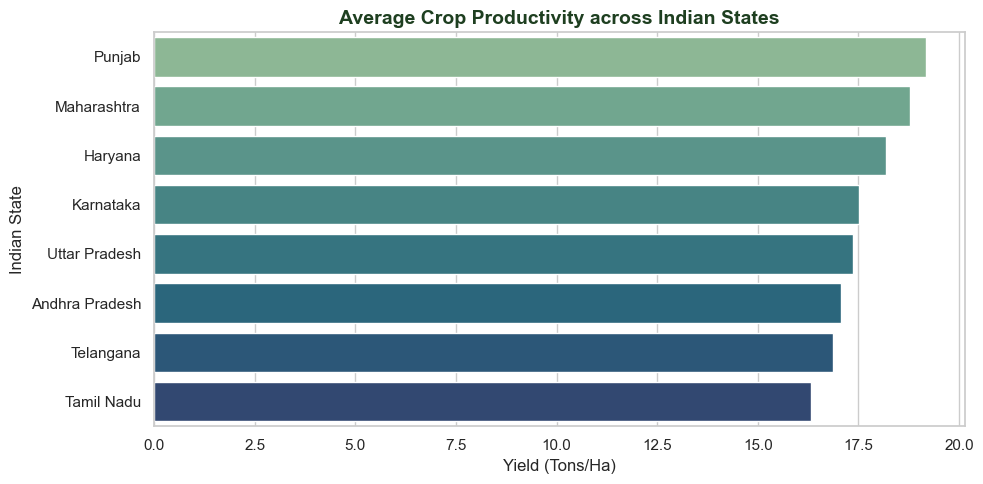

In [5]:
plt.figure(figsize=(10, 5))
state_yield = df.groupby('state')['yield'].mean().sort_values(ascending=False)
sns.barplot(x=state_yield.values, y=state_yield.index, palette="crest")
plt.title("Average Crop Productivity across Indian States", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Yield (Tons/Ha)", fontsize=12)
plt.ylabel("Indian State", fontsize=12)
plt.tight_layout()
plt.show()

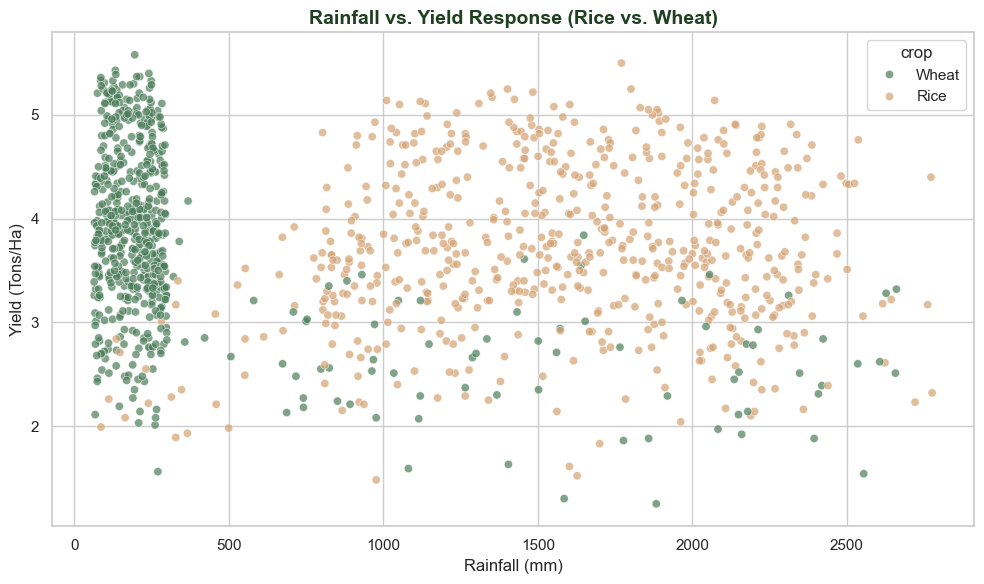

In [6]:
plt.figure(figsize=(10, 6))
# Visualizing contrasting crops: Rice (high moisture preferred) vs Wheat (low moisture preferred)
sub_df = df[df['crop'].isin(['Rice', 'Wheat'])]
sns.scatterplot(data=sub_df, x='rainfall', y='yield', hue='crop', alpha=0.7, palette=['#4A7C59', '#D4A373'])
plt.title("Rainfall vs. Yield Response (Rice vs. Wheat)", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Rainfall (mm)", fontsize=12)
plt.ylabel("Yield (Tons/Ha)", fontsize=12)
plt.tight_layout()
plt.show()

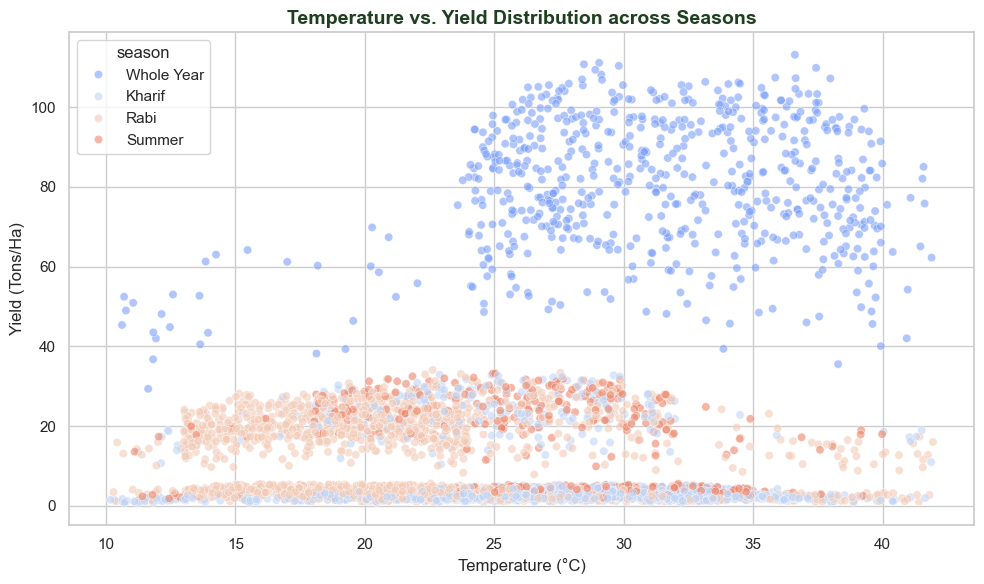

In [7]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='temperature', y='yield', hue='season', alpha=0.6, palette="coolwarm")
plt.title("Temperature vs. Yield Distribution across Seasons", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Temperature (°C)", fontsize=12)
plt.ylabel("Yield (Tons/Ha)", fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\sanga\AppData\Local\Temp\ipykernel_28320\756241333.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='soil_type', y='yield', palette="Set2")


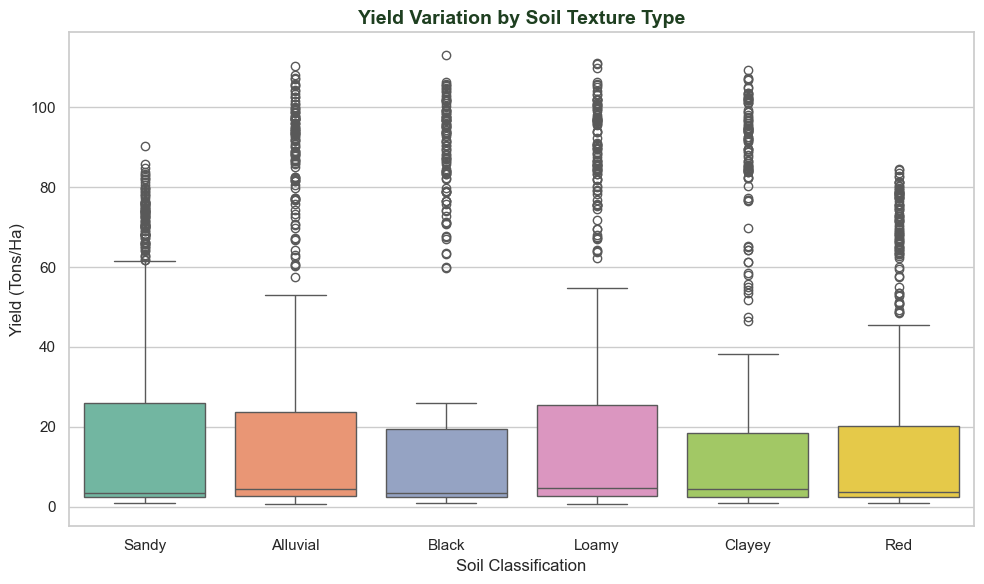

In [8]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='soil_type', y='yield', palette="Set2")
plt.title("Yield Variation by Soil Texture Type", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Soil Classification", fontsize=12)
plt.ylabel("Yield (Tons/Ha)", fontsize=12)
plt.tight_layout()
plt.show()

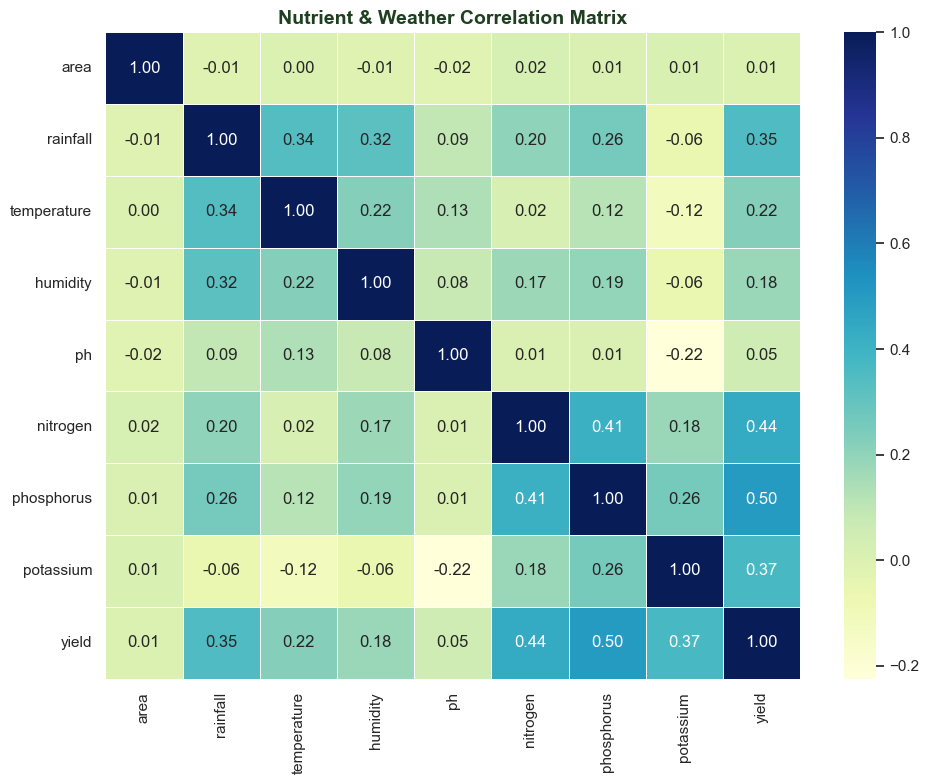

In [9]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=0.5)
plt.title("Nutrient & Weather Correlation Matrix", fontsize=14, fontweight='bold', color='#1E3F20')
plt.tight_layout()
plt.show()

### ⚙️ Feature Engineering & Preprocessing
We enrich the feature space by creating agronomic features:
1. **`NPK_Total`**: Combined N, P, K quantity in the soil (total chemical inputs index).
2. **`temp_humidity_ratio`**: Ratio indicating evapotranspiration rates.
3. **`rain_temp_ratio`**: Ratio of moisture index.

In [10]:
# Create agronomic feature combinations
df['NPK_Total'] = df['nitrogen'] + df['phosphorus'] + df['potassium']
df['temp_humidity_ratio'] = df['temperature'] / (df['humidity'] + 1)
df['rain_temp_ratio'] = df['rainfall'] / (df['temperature'] + 1)

print("Engineered Features Created! Dimensions:", df.shape)
display(df[['nitrogen', 'phosphorus', 'potassium', 'NPK_Total', 'temp_humidity_ratio', 'rain_temp_ratio']].head())

Engineered Features Created! Dimensions: (5000, 17)


,nitrogen,phosphorus,potassium,NPK_Total,temp_humidity_ratio,rain_temp_ratio
0,176.60,65.62,60.91,303.13,0.360513,73.786090
1,107.39,27.32,56.45,191.16,0.744966,22.956949
2,132.75,47.94,129.75,310.44,0.315421,111.590083
3,29.43,28.57,59.72,117.72,0.904939,30.576834
4,123.21,55.30,75.58,254.09,0.388164,31.561519


### 🔠 Encoding Categoricals & Standard Scaling
- Categorical strings (`state`, `district`, `crop`, `season`, `soil_type`) are encoded into index categories using Scikit-Learn's `LabelEncoder`.
- Numerical values are scaled using `StandardScaler` to speed up and stabilize model training coefficients.

In [11]:
cat_cols = ['state', 'district', 'crop', 'season', 'soil_type']
label_encoders = {}
df_encoded = df.copy()

for col in cat_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f"Encoded '{col}' successfully.")

# Split features X and target label y
X = df_encoded.drop(columns=['yield'])
y = df_encoded['yield']
feature_columns = list(X.columns)

# Standardize numeric inputs
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nAll categorical inputs encoded, numeric features scaled.")
print(f"Final X shape: {X_scaled.shape}")

Encoded 'state' successfully.
Encoded 'district' successfully.
Encoded 'crop' successfully.
Encoded 'season' successfully.
Encoded 'soil_type' successfully.

All categorical inputs encoded, numeric features scaled.
Final X shape: (5000, 16)


### 🤖 Random Forest Regressor Model Training
We divide the dataset into an **80-20 train-test split** and fit a **Random Forest Regressor** model.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

# Initialize model
rf_model = RandomForestRegressor(n_estimators=150, max_depth=16, random_state=42, n_jobs=-1)
print("Fitting Random Forest Model...")
rf_model.fit(X_train, y_train)
print("Model training finished successfully!")

Training set: 4000 samples
Testing set: 1000 samples
Fitting Random Forest Model...
Model training finished successfully!


### 📈 Model Evaluation Metrics
We inspect the Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Coefficient of Determination ($R^2$ Score) to gauge prediction accuracy.

In [13]:
# Perform prediction
y_pred = rf_model.predict(X_test)

# Compute metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Performance Summary ---")
print(f"Mean Absolute Error (MAE)   : {mae:.4f} Tons/Ha")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f} Tons/Ha")
print(f"R² Score (Model Fit Accuracy) : {r2:.4f} ({r2*100:.2f}%)")

--- Model Evaluation Performance Summary ---
Mean Absolute Error (MAE)   : 1.0520 Tons/Ha
Root Mean Squared Error (RMSE) : 2.3618 Tons/Ha
R² Score (Model Fit Accuracy) : 0.9921 (99.21%)


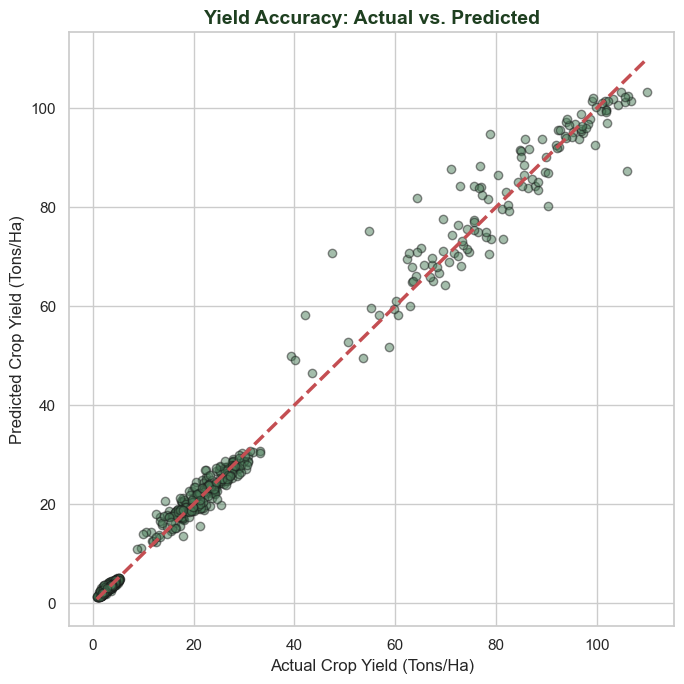

In [14]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.5, color='#4A7C59', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5)
plt.title("Yield Accuracy: Actual vs. Predicted", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Actual Crop Yield (Tons/Ha)", fontsize=12)
plt.ylabel("Predicted Crop Yield (Tons/Ha)", fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\sanga\AppData\Local\Temp\ipykernel_28320\3294624644.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=sorted_features, palette="summer")


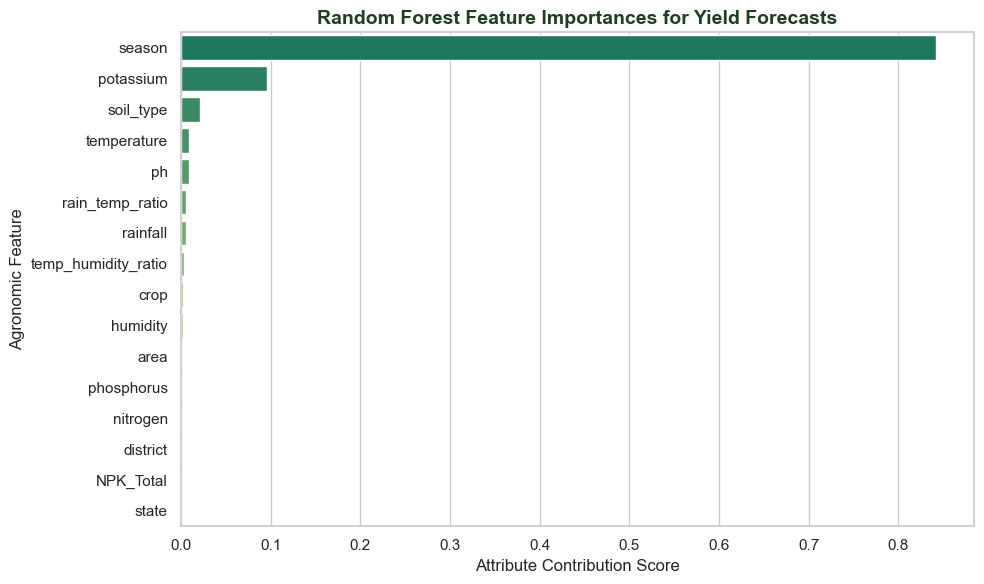

In [15]:
plt.figure(figsize=(10, 6))
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
sorted_features = [feature_columns[i] for i in indices]

sns.barplot(x=importances[indices], y=sorted_features, palette="summer")
plt.title("Random Forest Feature Importances for Yield Forecasts", fontsize=14, fontweight='bold', color='#1E3F20')
plt.xlabel("Attribute Contribution Score", fontsize=12)
plt.ylabel("Agronomic Feature", fontsize=12)
plt.tight_layout()
plt.show()

### 💾 Model Serialization
To build our interactive farming dashboard, we write our trained model, label encoders, standard scaler, and columns index to the disk using `joblib` files.

In [16]:
# Export joblib artifacts
joblib.dump(rf_model, "yield_prediction_model.joblib")
joblib.dump(label_encoders, "label_encoders.joblib")
joblib.dump(scaler, "scaler.joblib")
joblib.dump(feature_columns, "feature_columns.joblib")

print("All ML artifacts exported successfully:")
print("- yield_prediction_model.joblib")
print("- label_encoders.joblib")
print("- scaler.joblib")
print("- feature_columns.joblib")

All ML artifacts exported successfully:
- yield_prediction_model.joblib
- label_encoders.joblib
- scaler.joblib
- feature_columns.joblib


### 🧠 Academic Viva Questions & Quick-Reference Answers

**Q1. What is the objective of this project?**  
*Answer*: To forecast crop yields (Tons/Hectare) based on weather factors (rainfall, temperature, humidity), soil health variables (soil type, pH), and primary soil nutrients (Nitrogen, Phosphorus, Potassium). This supports precision farming by giving farmers quantitative insights to optimize resources.

**Q2. Why did you choose Random Forest Regressor over simple Linear Regression?**  
*Answer*: Crop yield forms a highly complex non-linear relationship with environmental inputs. For instance, too little or too much rainfall decreases yield. Linear regression cannot capture these complex peaks and optimal thresholds, whereas Random Forest, as an ensemble decision-tree method, excels at capturing high-dimensional non-linear interactions.

**Q3. How did you handle categorical attributes like State, District, and Crop?**  
*Answer*: We utilized Scikit-Learn's `LabelEncoder` to translate category strings into unique integer tokens. These encoders were saved to disk and are loaded dynamically by the Tkinter desktop GUI to process dropdown selections.

**Q4. What is the role of feature scaling (StandardScaler)?**  
*Answer*: It centers and scales each numerical column to have a mean of 0 and standard deviation of 1. This ensures that features with larger numeric scales (e.g., Rainfall in thousands of mm) do not disproportionately bias the learning algorithm over smaller scales (e.g., pH).